# Homework 1: Finding Similar Items (textually similar documents)

Group 28

## How to run

1. Use Python 3.11 and install the libraries in `requirements.txt`:
   ```
   pip install -r requirements.txt
   ```
2. Open `shingle.ipynb` in Jupyter or VS Code and click **Run All**.
3. The first time it needs internet, because it downloads the dataset into `data/`. After that it works offline.

Running everything takes a few minutes (most of it is the run with 5000 documents).

## Parameters

There are no command-line parameters, they are variables in the notebook:

| parameter | value | where |
|---|---|---|
| k (letters per shingle) | 5 | `K` in the experiments cell |
| n (length of the signature) | 100 | `N_HASHES` in the experiments cell |
| s (similarity threshold) | 0.8 | `S` in the experiments cell |
| r (rows in each band of LSH) | 5, so there are b = 100 / 5 = 20 bands | `BAND_SIZE` in the experiments cell |
| seed of the hash functions | 42 | `Minhashing(n, seed=42)` |
| number of documents tested | 10, 100, 500, 1000, 5000 | experiments cell |
| documents used in graphs 3 and 4 | first 1000 | graph 3 cell |

## Solution description

- **Shingle**: first we put the text in lowercase and leave only one space between words. Then we take every substring of k letters and keep them in a set so there are no duplicates. If the message is shorter than k (like "Ok"), the whole message is its only shingle, so the set is never empty. To hash a shingle we use sha256 and keep the first 4 bytes, so each shingle becomes a number between 0 and 2^32.
- **CompareSets**: computes the Jaccard similarity of two sets: the number of elements in common divided by the number of elements in the union.
- **Minhashing**: makes n hash functions h(x) = (a*x + b) % p, with random a and b and p a prime bigger than 2^32. Each function works like a random permutation of the rows: h(x) is the new position of shingle x. For each function we keep the minimum value over the shingles of the document, which is the first row with a 1 after shuffling. The n minimums are the signature.
- **CompareSignatures**: counts in how many positions the two signatures have the same number and divides by n. This is an estimate of the Jaccard similarity, because the probability that the minimums are equal is the Jaccard similarity. Both signatures need the same Minhashing object, because the positions only mean the same thing if they come from the same hash functions.
- **LSH**: cuts every signature in bands of r numbers (`bandSize`) and hashes each band to get its bucket. We keep one dictionary per band with the documents that fell in each bucket, so two documents only meet if they are equal in the same band. Two documents are candidates if they are in the same bucket in at least one band. In the end we only compare the signatures of the candidates and keep the ones that agree in at least a fraction s of the positions. We save the number of the document (not the signature), so repeated messages are not lost.
- **find_similar_documents**: runs everything on a list of documents. It compares every pair with Jaccard (real similarity), every pair of signatures (estimated similarity) and, with LSH, only the candidate pairs. It keeps the pairs with similarity >= s and measures how long each step takes.

In [1]:
import hashlib
import os
import random
import time
import urllib.request
import zipfile

import pandas as pd

In [2]:
class Shingle():
    
    def __init__(self,k,doc):   
        self.k = k  #number of letters of each shingle
        self.doc = doc
        self.shingles = set()   
        words = " ".join(word.lower() for word in doc.split()) 
        if len(words) < k:
            # message shorter than k (like "Ok"): the whole text is its only shingle,
            # if not the set would be empty and min() would fail in minhashing
            self.shingles.add(words)
            return
        noofshingles = (len(words) - k) +1 #stop at last possible shingle letter (number of shingles in the text)
        for i in range(noofshingles): 
            shingle = words[i:i+k]
            self.shingles.add(shingle)  #its a set so there are no duplicates

    def hashes(self):
        s = sorted(int.from_bytes(hashlib.sha256(shingle.encode("utf-8")).digest()[:4]) for shingle in self.shingles)  #converts each shingle in a number
        return set(s)

In [3]:
class CompareSets():
    def sim(self,a,b):
        return len(a.intersection(b)) / len(a.union(b))   #number of elements in common divided by total number of elements 

In [4]:
class Minhashing():
    # makes the minhash signature of a document (a list of n numbers) from its set of hashed shingles
    # each hash function h(x) = (a*x + b) % p works like one permutation of the rows:
    # h(x) is the new position of shingle x after shuffling
    def __init__(self, n, seed=42):
        # n = length of the signature = number of hash functions (permutations)
        self.rng = random.Random(seed)   #for reproducibility (always the same functions)
        self.hashFunctions = self.createHashFunctions(n)

    def signature(self, hashSet):
        # hashSet = hashed shingles of one document (from Shingle.hashes())
        sig = []
        for h in self.hashFunctions:                  # one permutation each time
            values = [h(x) for x in hashSet]          # new position of every shingle of the document
            sig.append(min(values))                   # the smallest one = first row with a 1 after shuffling
        return sig

    def createHashFunctions(self, n):
        # makes n random hash functions h(x) = (a*x + b) % p
        funcs = []
        p = 4294967311  # first prime after 2^32, so it is bigger than any shingle hash
        for _ in range(n):
            a = self.rng.randint(1, p - 1)
            b = self.rng.randint(0, p - 1)
            f = lambda x, a=a, b=b: (a * x + b) % p  #function with different a and different b every time
            funcs.append(f)
        return funcs


In [5]:
class CompareSignatures():
    # estimated similarity = fraction of positions where the two signatures have the same number
    # both signatures have to be made with the same Minhashing object (same hash functions)
    def sim(self, sig1, sig2):
        if len(sig1) != len(sig2):
            raise ValueError("Signatures must have the same length")
        agree = 0
        for x, y in zip(sig1, sig2):   # goes through both lists at the same time
            if x == y:
                agree += 1
        return agree / len(sig1)

In [6]:
import itertools

class LSH():
    # two documents are candidates if they are equal in at least one band (same bucket)
    def __init__(self,signatures,s,bandSize=5):
        if len(signatures[0])% bandSize!=0:
             raise ValueError("n has to be divisible by bandSize")  #if not the last band would be shorter and the last band will give more candidates and it would take longer time, but nothing wrong would happen
        self.signatures= signatures   #list of signatures, position i = document i
        self.s=s
        self.bandSize = bandSize
        self.sortedBucket = {}   #has to exist before sortBuckets() uses it
        self.bands = {doc:self.banding(signature) for doc,signature in enumerate(signatures)}  #key = number of the document, not the signature (if not repeated documents are lost)
        self.sortBuckets()   #fills self.sortedBucket (it returns nothing, so we don't save the result)


    def banding(self,signature): #convert array into bands
        bands = [ signature[x:(x+self.bandSize)] for x in range(0,len(signature),self.bandSize)]
        buckets = [hash(tuple(band)) for band in bands]   #number of the bucket of each band
        return buckets

    def sortBuckets(self):
            for doc,bands in self.bands.items():
                for bandIndex,bandHash in enumerate(bands):
                    if bandIndex not in self.sortedBucket:
                         self.sortedBucket[bandIndex] = {}
                    if bandHash not in self.sortedBucket[bandIndex]:
                         self.sortedBucket[bandIndex][bandHash] = set()
                    self.sortedBucket[bandIndex][bandHash].add(doc)
     #sortedBucket= {
     # band 0 : {10:(doc 0 , doc 1),30:(doc 2)}
     # band 1  : {20:(doc 0 , doc 1,doc 2)}
     #}
     #

    def returnCandidates(self):
         candidateSet = set()
         for bandIndex in self.sortedBucket:
            for bandHash in self.sortedBucket[bandIndex]:
                 docs = self.sortedBucket[bandIndex][bandHash] #set of documents -> gen pairs from these
                 #combinations(list, 2) gives every pair of the list once, without repeating: combinations([0,1,2],2) -> (0,1),(0,2),(1,2)
                 #if the bucket has only one document it gives no pairs
                 for pair in itertools.combinations(sorted(docs),2):  #sorted so the pair is always (i, j) with i < j
                      candidateSet.add(pair)
         return candidateSet

    def similarPairs(self):
         #candidates can be false positives, so we check the fraction of equal positions
         compare = CompareSignatures()
         result = {}
         for i,j in self.returnCandidates():
              sim = compare.sim(self.signatures[i],self.signatures[j])
              if sim >= self.s:
                   result[(i,j)] = sim
         return result


#((doc 0,doc 1), (doc 0,doc 2) , (doc 1, doc 2)))

In [7]:
# small test with "apple" and "aple" (k = 3)
a = {1,2,3}
b = {1,2,3}
print("Jaccard of two equal sets:", CompareSets().sim(a, b))

apple = Shingle(3, "apple").hashes()
aple = Shingle(3, "aple").hashes()

m = Minhashing(100)
sa = m.signature(apple)
sb = m.signature(aple)
print("length of the signature:", len(sa))

m2 = Minhashing(1000)
sa2 = m2.signature(apple)
sb2 = m2.signature(aple)

m3 = Minhashing(10000)
sa3 = m3.signature(apple)
sb3 = m3.signature(aple)

# compare the real Jaccard similarity with the estimate from the signatures
print("Jaccard (real):                ", CompareSets().sim(apple, aple))
print("Signatures 100 (estimate):     ", CompareSignatures().sim(sa, sb))
print("Signatures 1000 (estimate):    ", CompareSignatures().sim(sa2, sb2))
print("Signatures 10000 (estimate):   ", CompareSignatures().sim(sa3, sb3))

Jaccard of two equal sets: 1.0
length of the signature: 100
Jaccard (real):                 0.25
Signatures 100 (estimate):      0.31
Signatures 1000 (estimate):     0.264
Signatures 10000 (estimate):    0.2577


## Dataset

We use the SMS Spam Collection from the UC Irvine Machine Learning Repository:
https://archive.ics.uci.edu/dataset/228/sms+spam+collection

It has 5574 SMS messages and each message is one document. A lot of spam messages are sent many times with small changes, so there are similar documents to find.

The dataset is not in the zip. The next cell downloads it into `data/` the first time it runs.

In [8]:
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
DATA_DIR = "data"

def load_sms_dataset():
    # Downloads the zip only if it is not already on disk, then returns the list of messages (documents).
    zip_path = os.path.join(DATA_DIR, "sms_spam_collection.zip")
    if not os.path.exists(zip_path):
        os.makedirs(DATA_DIR, exist_ok=True)
        print("Downloading dataset...")
        urllib.request.urlretrieve(DATA_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        text = z.read("SMSSpamCollection").decode("utf-8")
    docs = []
    for line in text.splitlines():
        label, message = line.split("\t", 1)   # split only on the first tab: "ham" / "spam" and the message
        docs.append(message)
    return docs

docs = load_sms_dataset()
print(len(docs), "documents")
docs[:3]

5574 documents


['Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...',
 'Ok lar... Joking wif u oni...',
 "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"]

## Finding similar documents

Steps:
1. Get the shingles of each document and hash them
2. Make the minhash signature of each document
3. Compare every pair of documents with Jaccard (real similarity)
4. Compare every pair of signatures (estimated similarity)
5. Use LSH to get the candidate pairs and compare only their signatures

Two documents are similar if the similarity is >= s.

We use k = 5 because the messages are short (lecture 2 says k = 5 is ok for short documents like emails), n = 100 and s = 0.8.

For LSH we use bands of r = 5 numbers, so there are b = 20 bands. A pair with similarity t is a candidate with probability 1 - (1 - t^5)^20, which is 0.9996 for t = 0.8, so almost no similar pair is lost. The curve goes up around (1/b)^(1/r) = (1/20)^(1/5) ≈ 0.55, lower than s. Because of this some pairs that are not similar are also candidates, but they are removed when we compare their signatures. Steps 3 and 4 are still there to check if LSH finds the right pairs and to compare the times.

In [9]:
def find_similar_documents(docs, k=5, n=100, s=0.8, band_size=5):
    times = {}

    # 1. Shingling: one set of hashed shingles per document
    start = time.perf_counter()
    shingle_sets = [Shingle(k, doc).hashes() for doc in docs]
    times["shingling (s)"] = time.perf_counter() - start

    # 2. Minhashing: one signature of length n per document
    start = time.perf_counter()
    minhashing = Minhashing(n)
    signatures = [minhashing.signature(hash_set) for hash_set in shingle_sets]
    times["minhashing (s)"] = time.perf_counter() - start

    compare_sets = CompareSets()
    compare_signatures = CompareSignatures()

    # 3. Exact Jaccard similarity of every pair (i, j) with i < j, so each pair is checked once
    start = time.perf_counter()
    jaccard_pairs = {}
    for i in range(len(docs)):
        for j in range(i + 1, len(docs)):
            sim = compare_sets.sim(shingle_sets[i], shingle_sets[j])
            if sim >= s:
                jaccard_pairs[(i, j)] = sim
    times["compare shingle sets - Jaccard (s)"] = time.perf_counter() - start

    # 4. Estimated similarity of every pair using the minhash signatures
    start = time.perf_counter()
    signature_pairs = {}
    for i in range(len(docs)):
        for j in range(i + 1, len(docs)):
            sim = compare_signatures.sim(signatures[i], signatures[j])
            if sim >= s:
                signature_pairs[(i, j)] = sim
    times["compare signatures (s)"] = time.perf_counter() - start

    # 5. LSH: puts the signatures in buckets by bands and only compares the candidate pairs
    #    (documents that are in the same bucket in at least one band), not every pair
    start = time.perf_counter()
    lsh = LSH(signatures, s, band_size)
    lsh_pairs = lsh.similarPairs()
    times["LSH (s)"] = time.perf_counter() - start
    candidates = len(lsh.returnCandidates())   # outside the time, it is only to count them

    return times, jaccard_pairs, signature_pairs, lsh_pairs, candidates




In [10]:
# computer used for the times below (the times depend on the computer)
import platform
import sys
print("Python:", sys.version.split()[0])
print("OS:    ", platform.platform())
print("CPU:   ", platform.processor())

Python: 3.11.0
OS:     Windows-10-10.0.26200-SP0
CPU:    Intel64 Family 6 Model 186 Stepping 2, GenuineIntel


In [11]:
# run everything with more and more documents and measure how long each step takes
K, N_HASHES, S, BAND_SIZE = 5, 100, 0.8, 5
results = []
for size in [10, 100, 500, 1000, 5000]:
    times, jaccard_pairs, signature_pairs, lsh_pairs, candidates = find_similar_documents(docs[:size], k=K, n=N_HASHES, s=S, band_size=BAND_SIZE)
    both = set(jaccard_pairs) & set(signature_pairs)
    results.append({
        "documents": size,
        **times,
        "total (s)": sum(times.values()),
        "similar pairs (Jaccard)": len(jaccard_pairs),
        "similar pairs (signatures)": len(signature_pairs),
        "found by both": len(both),
        "false positives": len(set(signature_pairs) - set(jaccard_pairs)),  # signatures say similar, Jaccard says no (jaccard was less than 0.8 and signatures was more)
        "false negatives": len(set(jaccard_pairs) - set(signature_pairs)),  # Jaccard says similar, signatures missed it
        "all pairs": size * (size - 1) // 2,   # pairs compared without LSH
        "candidates (LSH)": candidates,        # pairs compared with LSH
        "similar pairs (LSH)": len(lsh_pairs),
        "false positives (LSH)": len(set(lsh_pairs) - set(jaccard_pairs)),  # LSH says similar, Jaccard says no
        "false negatives (LSH)": len(set(jaccard_pairs) - set(lsh_pairs)),  # Jaccard says similar, LSH missed it
        "missed by banding": len(set(signature_pairs) - set(lsh_pairs)),    # signatures agree in >= s but they were never in the same bucket
    })

results_df = pd.DataFrame(results).round(3)
results_df

,documents,shingling (s),minhashing (s),compare shingle sets - Jaccard (s),compare signatures (s),LSH (s),total (s),similar pairs (Jaccard),similar pairs (signatures),found by both,false positives,false negatives,all pairs,candidates (LSH),similar pairs (LSH),false positives (LSH),false negatives (LSH),missed by banding
0,10,0.001,0.027,0.000,0.000,0.000,0.029,0,0,0,0,0,45,0,0,0,0,0
1,100,0.007,0.138,0.021,0.011,0.002,0.179,0,0,0,0,0,4950,1,0,0,0,0
2,500,0.036,0.652,0.488,0.293,0.008,1.476,15,15,14,1,1,124750,32,15,1,1,0
3,1000,0.072,1.316,2.014,1.176,0.018,4.596,40,40,39,1,1,499500,81,40,1,1,0
4,5000,0.349,6.254,51.648,32.694,0.126,91.070,939,946,928,18,11,12497500,1522,946,18,11,0


In [12]:
# summary of the times of this run, used in the conclusions
# it is calculated from the table above, so it always matches the run (the times change every time we run it)
t = pd.DataFrame(results).set_index("documents")   # not rounded
small, big = 1000, 5000

print(f"From {small} to {big} documents the number of pairs grows {t.loc[big, 'all pairs'] / t.loc[small, 'all pairs']:.0f} times.")
# average number of shingles of a document (to compare with the n = 100 numbers of a signature)
for size in [small, big]:
    avg_shingles = sum(len(Shingle(K, doc).shingles) for doc in docs[:size]) / size
    print(f"Average number of shingles with {size} documents: {avg_shingles:.1f} (a signature has {N_HASHES} numbers)")
print("Time of each step and how many times it grows:")
for step in ["shingling (s)", "minhashing (s)", "compare shingle sets - Jaccard (s)", "compare signatures (s)", "LSH (s)"]:
    print(f"  {step:<36} {t.loc[small, step]:8.3f} s -> {t.loc[big, step]:8.3f} s   ({t.loc[big, step] / t.loc[small, step]:.0f} times)")

# total time of each way (the same as graph 2)
ways = pd.DataFrame({
    "Jaccard": t["shingling (s)"] + t["compare shingle sets - Jaccard (s)"],
    "signatures": t["shingling (s)"] + t["minhashing (s)"] + t["compare signatures (s)"],
    "LSH": t["shingling (s)"] + t["minhashing (s)"] + t["LSH (s)"],
})
print("\nFastest way for each number of documents:")
for size, way in ways.idxmin(axis=1).items():
    print(f"  {size:>5} documents: {way}")

print(f"\nWith {big} documents:")
print(f"  total time: Jaccard {ways.loc[big, 'Jaccard']:.1f} s, signatures {ways.loc[big, 'signatures']:.1f} s, LSH {ways.loc[big, 'LSH']:.1f} s")
print(f"  the LSH way is {ways.loc[big, 'Jaccard'] / ways.loc[big, 'LSH']:.0f} times faster than Jaccard and {ways.loc[big, 'signatures'] / ways.loc[big, 'LSH']:.0f} times faster than signatures")
print(f"  minhashing is {t.loc[big, 'minhashing (s)'] / ways.loc[big, 'LSH'] * 100:.0f}% of the time of the LSH way")
print(f"  LSH (step 5) is {t.loc[big, 'compare signatures (s)'] / t.loc[big, 'LSH (s)']:.0f} times faster than compare signatures (step 4)")

From 1000 to 5000 documents the number of pairs grows 25 times.
Average number of shingles with 1000 documents: 76.6 (a signature has 100 numbers)
Average number of shingles with 5000 documents: 74.2 (a signature has 100 numbers)
Time of each step and how many times it grows:
  shingling (s)                           0.072 s ->    0.349 s   (5 times)
  minhashing (s)                          1.316 s ->    6.254 s   (5 times)
  compare shingle sets - Jaccard (s)      2.014 s ->   51.648 s   (26 times)
  compare signatures (s)                  1.176 s ->   32.694 s   (28 times)
  LSH (s)                                 0.018 s ->    0.126 s   (7 times)

Fastest way for each number of documents:
     10 documents: Jaccard
    100 documents: Jaccard
    500 documents: Jaccard
   1000 documents: LSH
   5000 documents: LSH

With 5000 documents:
  total time: Jaccard 52.0 s, signatures 39.3 s, LSH 6.7 s
  the LSH way is 8 times faster than Jaccard and 6 times faster than signatures
  minhashi

In [13]:
# similar pairs found with 5000 documents (the last run), with the real and the estimated similarity
rows = []
for (i, j) in sorted(set(jaccard_pairs) | set(signature_pairs)):
    rows.append({
        "doc i": i,
        "doc j": j,
        "Jaccard": round(CompareSets().sim(Shingle(K, docs[i]).hashes(), Shingle(K, docs[j]).hashes()), 3),  #here we could have written  "<s" for false positives but we are going to calculate it instead
        "signatures": signature_pairs.get((i, j), "< s"),  #here we choose not to recalculate it
        "text i": docs[i],
        "text j": docs[j],
    })
pd.set_option("display.max_colwidth", 100)
pd.DataFrame(rows).sort_values("Jaccard").head(15)

,doc i,doc j,Jaccard,signatures,text i,text j
875,3266,3595,0.751,0.83,"44 7732584351, Do you want a New Nokia 3510i colour phone DeliveredTomorrow? With 300 free minut...",Do you want a New Nokia 3510i Colour Phone Delivered Tomorrow? With 200 FREE minutes to any mobi...
57,135,474,0.760,0.8,Want 2 get laid tonight? Want real Dogging locations sent direct 2 ur mob? Join the UK's largest...,Want 2 get laid tonight? Want real Dogging locations sent direct 2 ur Mob? Join the UK's largest...
112,250,4577,0.760,0.83,Congratulations ur awarded 500 of CD vouchers or 125gift guaranteed & Free entry 2 100 wkly draw...,Congratulations ur awarded 500 of CD vouchers or 125gift guaranteed & Free entry 2 100 wkly draw...
171,357,4577,0.760,0.83,Congratulations ur awarded 500 of CD vouchers or 125gift guaranteed & Free entry 2 100 wkly draw...,Congratulations ur awarded 500 of CD vouchers or 125gift guaranteed & Free entry 2 100 wkly draw...
322,838,2380,0.763,0.85,"Sir, I have been late in paying rent for the past few months and had to pay a $ &lt;#&gt; charg...","Good evening Sir, hope you are having a nice day. I wanted to bring it to your notice that I hav..."
348,962,2686,0.773,0.86,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....
368,1072,1673,0.773,0.82,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....
831,2686,3468,0.773,0.86,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....
61,167,3807,0.778,0.8,URGENT! We are trying to contact you. Last weekends draw shows that you have won a £900 prize GU...,URGENT! We are trying to contact you. Last weekends draw shows that you have won a £900 prize GU...
347,962,1673,0.784,0.87,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....,URGENT! We are trying to contact U. Todays draw shows that you have won a £800 prize GUARANTEED....


## Graphs

**Graph 1** shows how long each step takes when there are more documents. Both axes are in log scale, so a line with slope 1 means the time grows linearly and a line with slope 2 means it grows quadratically. The LSH line is the time of step 5 (making the buckets and comparing the candidates).

**Graph 2** shows the total time of the three ways of finding the similar pairs, adding the times of the steps that each way needs:
- Jaccard: shingling + compare shingle sets
- signatures: shingling + minhashing + compare signatures
- LSH: shingling + minhashing + LSH (LSH already includes comparing the signatures of the candidates)

**Graph 3** checks if minhashing works: each dot is a pair of documents, with the real Jaccard similarity on the x axis and the similarity estimated with the signatures on the y axis. If the estimate is good, the dots are close to the diagonal.

**Graph 4** is the S-curve of LSH: the probability that a pair becomes a candidate depending on its similarity. The lines are the theory, 1 - (1 - t^r)^b, for our choice (b = 20, r = 5) and for b = 10, r = 10. The dots are what really happened with the pairs of graph 3: we put the pairs in groups by their Jaccard similarity (0-0.1, 0.1-0.2, ...) and count how many of each group were candidates. The number over each dot is how many pairs are in that group.

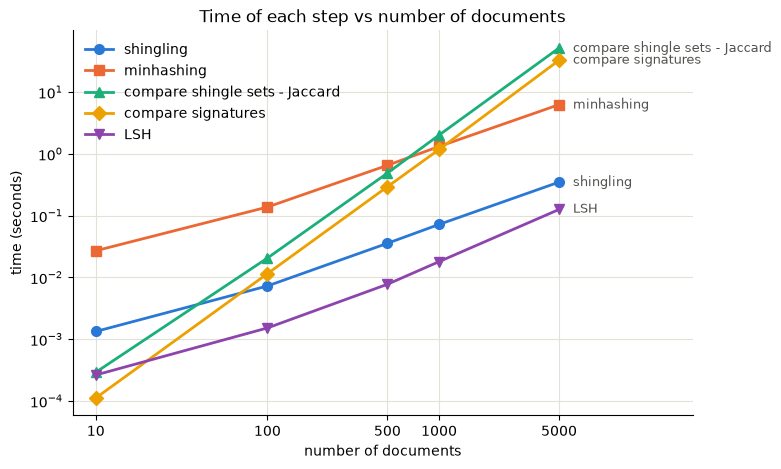

In [14]:
import matplotlib.pyplot as plt

# graph 1: time of each step vs number of documents
times_df = pd.DataFrame(results)   # not rounded, because a log scale can't show 0
steps = ["shingling (s)", "minhashing (s)", "compare shingle sets - Jaccard (s)", "compare signatures (s)", "LSH (s)"]   # names have to be the same as in find_similar_documents
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8e44ad"]
markers = ["o", "s", "^", "D", "v"]

fig, ax = plt.subplots(figsize=(8, 5))
for step, color, marker in zip(steps, colors, markers):
    name = step.replace(" (s)", "")
    ax.plot(times_df["documents"], times_df[step], color=color, marker=marker, linewidth=2, markersize=7, label=name)
    # write the name at the end of each line
    ax.annotate(name, (times_df["documents"].iloc[-1], times_df[step].iloc[-1]),
                xytext=(10, 0), textcoords="offset points", va="center", fontsize=9, color="#52514e")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(times_df["documents"])
ax.set_xticklabels(times_df["documents"])
ax.minorticks_off()
ax.set_xlim(right=times_df["documents"].max() * 6)   # space for the names at the end of the lines
ax.set_xlabel("number of documents")
ax.set_ylabel("time (seconds)")
ax.set_title("Time of each step vs number of documents")
ax.grid(True, color="#e1e0d9", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper left", frameon=False)
plt.show()

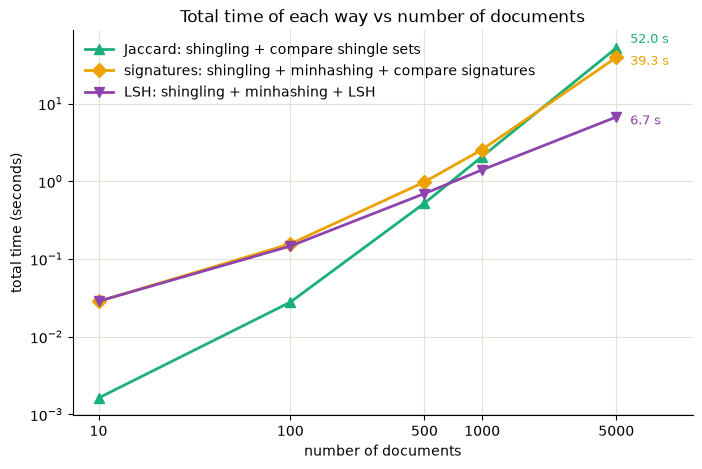

,documents,Jaccard: shingling + compare shingle sets,signatures: shingling + minhashing + compare signatures,LSH: shingling + minhashing + LSH
0,10,0.002,0.028,0.029
1,100,0.028,0.157,0.147
2,500,0.523,0.981,0.695
3,1000,2.086,2.564,1.406
4,5000,51.997,39.296,6.728


In [15]:
# graph 2: total time of each way of finding the similar pairs vs number of documents
# each line adds the times of the steps that this way needs (times_df comes from graph 1)
pipelines = {
    "Jaccard: shingling + compare shingle sets": times_df["shingling (s)"] + times_df["compare shingle sets - Jaccard (s)"],
    "signatures: shingling + minhashing + compare signatures": times_df["shingling (s)"] + times_df["minhashing (s)"] + times_df["compare signatures (s)"],
    "LSH: shingling + minhashing + LSH": times_df["shingling (s)"] + times_df["minhashing (s)"] + times_df["LSH (s)"],
}
colors = ["#1baf7a", "#eda100", "#8e44ad"]   # same color as the last step of each way in graph 1
markers = ["^", "D", "v"]

fig, ax = plt.subplots(figsize=(8, 5))
for (name, total), color, marker in zip(pipelines.items(), colors, markers):
    ax.plot(times_df["documents"], total, color=color, marker=marker, linewidth=2, markersize=7, label=name)
    # write the exact total time at the last point (the biggest number of documents)
    # the highest one goes a bit up, because the two slow ways end very close and the texts touch
    up = 6 if total.iloc[-1] == max(t.iloc[-1] for t in pipelines.values()) else -3
    ax.annotate(f"{total.iloc[-1]:.1f} s", (times_df["documents"].iloc[-1], total.iloc[-1]),
                xytext=(10, up), textcoords="offset points", va="center", fontsize=9, color=color)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(times_df["documents"])
ax.set_xticklabels(times_df["documents"])
ax.minorticks_off()
ax.set_xlim(right=times_df["documents"].max() * 2.5)   # space for the times at the end of the lines
ax.set_xlabel("number of documents")
ax.set_ylabel("total time (seconds)")
ax.set_title("Total time of each way vs number of documents")
ax.grid(True, color="#e1e0d9", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper left", frameon=False)
plt.show()

# the same numbers in a table
pd.DataFrame({"documents": times_df["documents"], **pipelines}).round(3)

499500 pairs
mean error: 0.0029
max error:  0.1315


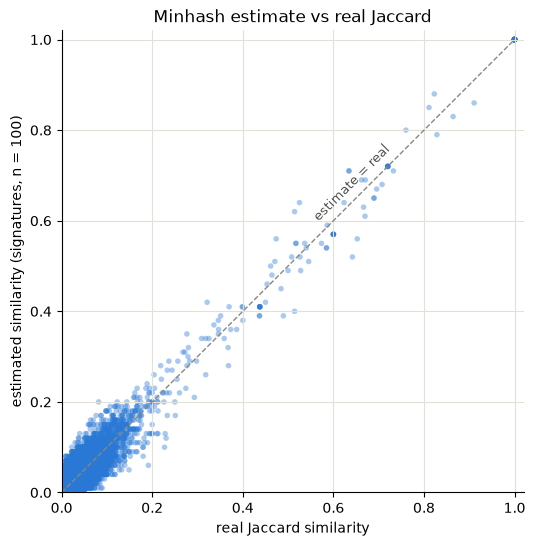

In [16]:
# graph 3: real Jaccard vs estimated similarity, for every pair of the first 1000 documents
sample = docs[:1000]
shingle_sets = [Shingle(K, doc).hashes() for doc in sample]
minhashing = Minhashing(N_HASHES)
signatures = [minhashing.signature(hash_set) for hash_set in shingle_sets]

compare_sets = CompareSets()
compare_signatures = CompareSignatures()
real = []
estimated = []
for i in range(len(sample)):
    for j in range(i + 1, len(sample)):
        real.append(compare_sets.sim(shingle_sets[i], shingle_sets[j]))
        estimated.append(compare_signatures.sim(signatures[i], signatures[j]))

errors = [abs(r - e) for r, e in zip(real, estimated)]
print(len(real), "pairs")
print("mean error:", round(sum(errors) / len(errors), 4))
print("max error: ", round(max(errors), 4))

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(real, estimated, s=16, color="#2a78d6", alpha=0.4, edgecolors="none")
ax.plot([0, 1], [0, 1], color="#898781", linestyle="--", linewidth=1)   # diagonal: estimate = real
ax.annotate("estimate = real", (0.55, 0.60), rotation=45, color="#52514e", fontsize=9)
ax.set_aspect("equal")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_xlabel("real Jaccard similarity")
ax.set_ylabel(f"estimated similarity (signatures, n = {N_HASHES})")
ax.set_title("Minhash estimate vs real Jaccard")
ax.grid(True, color="#e1e0d9", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

threshold (1/b)^(1/r): 0.55
81 candidates of 499500 pairs


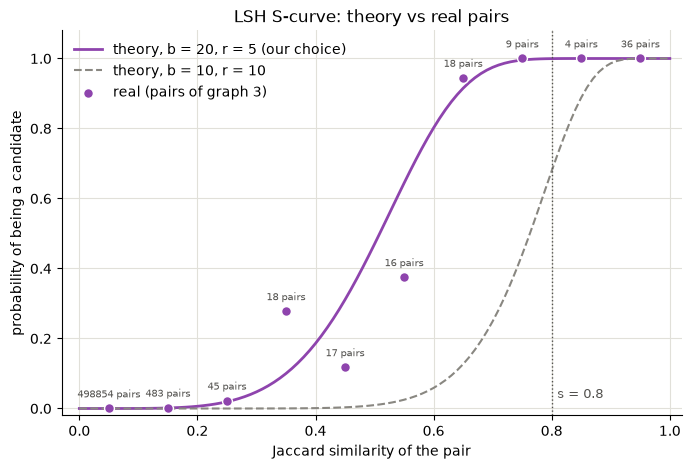

In [17]:
# graph 4: S-curve of LSH, probability that a pair becomes a candidate depending on its similarity
# we use the same 1000 documents as graph 3 (sample, signatures and real come from that cell)
BANDS = N_HASHES // BAND_SIZE   # b = 100 / 5 = 20 bands of r = 5 rows
sample_candidates = LSH(signatures, S, BAND_SIZE).returnCandidates()
print("threshold (1/b)^(1/r):", round((1 / BANDS) ** (1 / BAND_SIZE), 2))
print(len(sample_candidates), "candidates of", len(real), "pairs")

# theory: a pair with similarity t is equal in one band with probability t^r,
# so it is a candidate (equal in at least one band) with probability 1 - (1 - t^r)^b
t = [x / 100 for x in range(101)]
theory = [1 - (1 - x ** BAND_SIZE) ** BANDS for x in t]
theory_10x10 = [1 - (1 - x ** 10) ** 10 for x in t]   # other option with the same n: b = 10 bands of r = 10

# real: we put the pairs of graph 3 in groups by their Jaccard (0-0.1, 0.1-0.2, ...) and count how many are candidates
pairs_in_group = [0] * 10
candidates_in_group = [0] * 10
pairs = itertools.combinations(range(len(sample)), 2)   # same order as the list real of graph 3 (i < j)
for (i, j), sim in zip(pairs, real):
    group = min(int(sim * 10), 9)   # a similarity of 1 goes to the last group
    pairs_in_group[group] += 1
    if (i, j) in sample_candidates:
        candidates_in_group[group] += 1
groups = [g for g in range(10) if pairs_in_group[g] > 0]   # skip empty groups (we can't divide by 0)
centers = [g / 10 + 0.05 for g in groups]
fraction = [candidates_in_group[g] / pairs_in_group[g] for g in groups]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t, theory, color="#8e44ad", linewidth=2, label=f"theory, b = {BANDS}, r = {BAND_SIZE} (our choice)")
ax.plot(t, theory_10x10, color="#898781", linewidth=1.5, linestyle="--", label="theory, b = 10, r = 10")
ax.scatter(centers, fraction, s=50, color="#8e44ad", edgecolors="white", zorder=3, label="real (pairs of graph 3)")
for x, y, g in zip(centers, fraction, groups):
    ax.annotate(f"{pairs_in_group[g]} pairs", (x, y), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=7, color="#52514e")   # how many pairs are in the group
ax.axvline(S, color="#52514e", linestyle=":", linewidth=1)
ax.annotate(f"s = {S}", (S, 0.03), xytext=(4, 0), textcoords="offset points", fontsize=9, color="#52514e")
ax.set_xlim(-0.03, 1.02)   # a bit of space so the text of the first dot is not cut
ax.set_ylim(-0.02, 1.08)
ax.set_xlabel("Jaccard similarity of the pair")
ax.set_ylabel("probability of being a candidate")
ax.set_title("LSH S-curve: theory vs real pairs")
ax.grid(True, color="#e1e0d9", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper left", frameon=False)
plt.show()

## Results and conclusions

The times depend on the computer and change every time we run the notebook (the computer we used is printed before the experiments). Because of this, here we explain what happens, and the exact times of the run are in the summary cell after the experiments table. The number of pairs, candidates and mistakes is always the same, because the hash functions use a fixed seed.

**Time of each step (graph 1).** Shingling and minhashing grow linearly, because each document is done once: with 5 times more documents they take about 5 times more. Compare sets and compare signatures grow quadratically, because they check every pair: from 1000 to 5000 documents the pairs go from 499,500 to about 12.5 million (25 times more), so these two steps take about 25 times more, or even more, because they take a long time and the computer is not always at the same speed.

LSH takes less than a second even with 5000 documents, much less than compare signatures. Its time is so small that anything else the computer is doing changes it a lot, so its line in graph 1 is not as regular as the others. It also grows because with more documents there are more repeated spam messages and so more candidates to compare (81 with 1000 documents and 1522 with 5000), but 1522 candidates is nothing compared to 12.5 million pairs.

**Total time (graph 2).** With few documents (500 or less) the fastest way is Jaccard, because minhashing takes more time than comparing the few pairs there are. From 1000 documents the LSH way is the fastest, and the difference grows a lot: with 5000 documents the other two ways take tens of seconds, and the LSH way only a few seconds. Almost all the time of the LSH way is minhashing.

The signatures way is not much faster than Jaccard here (depending on the run it is a bit faster or a bit slower), because SMS messages are short: they have 74 shingles on average, fewer than the 100 numbers of a signature, so comparing signatures doesn't save much work. With long documents (thousands of shingles) it would.

**Quality of the estimate (graph 3 and table).** The estimate is very good: the dots are close to the diagonal and the mean error is 0.003. With 5000 documents there are 939 similar pairs and only 18 false positives and 11 false negatives, and all of them have a Jaccard close to 0.8: between 0.75 and 0.80 the false positives and between 0.80 and 0.85 the false negatives. This happens because the estimate has a small error, so a pair with 0.78 can be estimated as 0.82 and the other way around. With a bigger n there would be fewer mistakes.

**Quality of LSH (table and graph 4).** LSH finds the same similar pairs as comparing every pair of signatures ("missed by banding" is 0 for all sizes). So its false positives and false negatives are the same as the ones of the signatures: they come from minhashing, not from LSH. Graph 4 shows why: the dots follow the theory curve, every pair with Jaccard above 0.7 was a candidate and almost no pair below 0.2 was (1 of more than 499,000). The dots in the middle are a bit far from the curve because those groups only have 16-18 pairs. With b = 10 and r = 10 the curve goes up closer to 0.8, so there would be fewer candidates, but a pair with similarity 0.8 would only be a candidate 68% of the times (1 - (1 - 0.8^10)^10 ≈ 0.68), so we would lose similar pairs. That is why we chose b = 20 and r = 5.

**What was found.** Most similar pairs are spam messages sent many times with small changes, like a different phone number or a word in capital letters.

## AI disclosure

We used Claude (by Anthropic), through Claude Code in VS Code, during this homework. We used it for:

- Support while programming
- Checking our code for errors
- Helping us understand the concepts (for example the S-curve of LSH)
- Drawing the graphs